# 01 EDA: IBM AML transactions (HI-Small)

**Goal:** understand the data well enough to choose a train, validation and test split and a first feature set.

**Dataset:** IBM Transactions for Anti Money Laundering, HI-Small variant (Altman et al., NeurIPS 2023). Synthetic data. Files live in `data/` and are not committed.

**Questions this notebook answers**
1. How many transactions are there, and how rare is laundering?
2. How is the data spread over time, and is any period unusable?
3. Which columns separate laundering too easily (shortcuts)?
4. What do amounts, currencies and self transfers look like?
5. How active are accounts, and do the accounts file and the transactions join cleanly?
6. What does the patterns file contain, and how much laundering does it cover?
7. Which split follows from all of this?

Each section ends with a short **Finding**.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data")
TRANS_FILE = DATA / "HI-Small_Trans.csv"
ACCOUNTS_FILE = DATA / "HI-Small_accounts.csv"
PATTERNS_FILE = DATA / "HI-Small_Patterns.txt"

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Load and schema

The raw header has two columns both called `Account`, so the columns are renamed on load. Bank IDs are read as integers because the file pads them with leading zeros inconsistently (for example `010`), and the accounts file stores them without padding.

In [2]:
TX_COLS = [
    "timestamp", "from_bank", "from_account", "to_bank", "to_account",
    "amount_received", "receiving_currency", "amount_paid",
    "payment_currency", "payment_format", "is_laundering",
]
TX_DTYPES = {
    "from_bank": "int32", "from_account": "category",
    "to_bank": "int32", "to_account": "category",
    "amount_received": "float64", "receiving_currency": "category",
    "amount_paid": "float64", "payment_currency": "category",
    "payment_format": "category", "is_laundering": "int8",
}

tx = pd.read_csv(TRANS_FILE, header=0, names=TX_COLS, dtype=TX_DTYPES)
tx["timestamp"] = pd.to_datetime(tx["timestamp"], format="%Y/%m/%d %H:%M")
tx["date"] = tx["timestamp"].dt.normalize()

print(f"rows: {len(tx):,}")
print(f"memory: {tx.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
tx.head()

rows: 5,078,345
memory: 351 MB


,timestamp,from_bank,from_account,to_bank,to_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,is_laundering,date
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,"3,697.3400",US Dollar,"3,697.3400",US Dollar,Reinvestment,0,2022-09-01
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.0100,US Dollar,0.0100,US Dollar,Cheque,0,2022-09-01
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,"14,675.5700",US Dollar,"14,675.5700",US Dollar,Reinvestment,0,2022-09-01
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,"2,806.9700",US Dollar,"2,806.9700",US Dollar,Reinvestment,0,2022-09-01
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,"36,682.9700",US Dollar,"36,682.9700",US Dollar,Reinvestment,0,2022-09-01


In [3]:
print(tx.dtypes)
print()
print("missing values per column:")
print(tx.isna().sum())
print()
print("exact duplicate rows:", f"{tx.duplicated().sum():,}")

timestamp             datetime64[ns]
from_bank                      int32
from_account                category
to_bank                        int32
to_account                  category
amount_received              float64
receiving_currency          category
amount_paid                  float64
payment_currency            category
payment_format              category
is_laundering                   int8
date                  datetime64[ns]
dtype: object

missing values per column:
timestamp             0
from_bank             0
from_account          0
to_bank               0
to_account            0
amount_received       0
receiving_currency    0
amount_paid           0
payment_currency      0
payment_format        0
is_laundering         0
date                  0
dtype: int64

exact duplicate rows: 9


**Finding:** The transactions file has 5,078,345 rows and 11 columns, with no missing values. The raw header has two columns named `Account`, so columns are renamed on load to separate the sending and receiving account. Bank IDs are read as integers because the transactions file pads them with leading zeros and the accounts file does not. Nine rows are exact duplicates. They are kept, because timestamps are recorded to the minute and two identical transfers within the same minute are plausible.

The sender and receiver mapping was verified in section 9: pairing each sending bank with the first account column matches the accounts file for 100% of a 200,000 row sample, and pairing it with the second matches 0%.

## 2. Label balance

In [4]:
n_pos = int(tx["is_laundering"].sum())
print(f"laundering rows: {n_pos:,} of {len(tx):,} ({n_pos / len(tx):.4%})")
print(f"one laundering row per {len(tx) / n_pos:,.0f} transactions")

laundering rows: 5,177 of 5,078,345 (0.1019%)
one laundering row per 981 transactions


With a positive rate this low, accuracy and ROC-AUC say very little. PR-AUC and recall at a fixed false positive rate are the metrics to use.

**Finding:** Only 5,177 of 5,078,345 transactions are laundering, about 0.10%, or roughly one in every 981. A model that labels every transaction as normal would be 99.9% accurate and detect nothing, so accuracy is not used. Models are compared on PR-AUC and on recall at a fixed false positive rate.

## 3. Time structure

A time based split needs to know how rows and laundering are spread across days.

In [5]:
daily = (
    tx.groupby("date")["is_laundering"]
    .agg(rows="size", laundering="sum")
    .assign(rate=lambda d: d["laundering"] / d["rows"])
)
daily

,rows,laundering,rate
date,,,
2022-09-01,1114921,322,0.0003
2022-09-02,754449,408,0.0005
2022-09-03,207382,391,0.0019
2022-09-04,207430,407,0.0020
2022-09-05,482650,471,0.0010
2022-09-06,482089,531,0.0011
2022-09-07,482751,497,0.0010
2022-09-08,482773,539,0.0011
2022-09-09,654467,514,0.0008


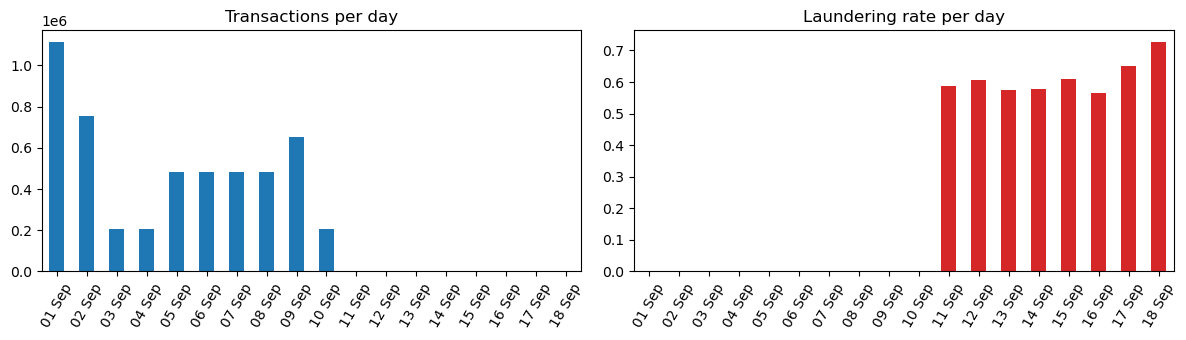

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
daily["rows"].plot.bar(ax=axes[0], title="Transactions per day")
daily["rate"].plot.bar(ax=axes[1], title="Laundering rate per day", color="tab:red")
for ax in axes:
    ax.set_xticklabels([d.strftime("%d %b") for d in daily.index], rotation=60)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [7]:
hourly = (
    tx.assign(hour=tx["timestamp"].dt.hour)
    .groupby("hour")["is_laundering"]
    .agg(rows="size", laundering="sum")
    .assign(rate=lambda d: d["laundering"] / d["rows"])
)
hourly

,rows,laundering,rate
hour,,,
0,634726,176,0.0003
1,193728,152,0.0008
2,193143,165,0.0009
3,193249,146,0.0008
4,193166,154,0.0008
5,193900,188,0.0010
6,194456,207,0.0011
7,193336,195,0.0010
8,192921,258,0.0013


Things to look for:
- Do the last days hold very few rows with a very high laundering rate? If so they cannot be an ordinary test set.
- Is the first day inflated by simulation start up?
- Is there a weekday and weekend pattern?

**Finding:** The data runs from 1 to 18 Sep 2022, but almost all of it falls in 1 to 10 Sep, with between 207,000 and 1,115,000 transactions a day. The last eight days hold only 1,108 rows in total, and 59% of them are laundering, against about 0.1% in the main period. This tail looks like laundering chains finishing after normal activity has stopped in the simulation, so it is not representative. It is held apart from the main split. Using it as a test set would let a model score well by learning the date. Within the main period, 1 Sep has about twice the volume of a typical weekday, weekends (3, 4 and 10 Sep) have less than half, and hour 0 has about three times the volume of any other hour. For these reasons the raw date and hour are treated with caution as features.

The tail holds 655 of the 5,177 laundering rows (about 13%), so most laundering sits inside the main period and holding the tail apart costs little training signal.

## 4. Payment format

Checked early because a categorical column that almost defines the label acts as a shortcut.

In [8]:
by_format = (
    tx.groupby("payment_format", observed=True)["is_laundering"]
    .agg(rows="size", laundering="sum")
    .assign(
        rate=lambda d: d["laundering"] / d["rows"],
        share_of_laundering=lambda d: d["laundering"] / d["laundering"].sum(),
    )
    .sort_values("laundering", ascending=False)
)
by_format

,rows,laundering,rate,share_of_laundering
payment_format,,,,
ACH,600797,4483,0.0075,0.8659
Cheque,1864331,324,0.0002,0.0626
Credit Card,1323324,206,0.0002,0.0398
Cash,490891,108,0.0002,0.0209
Bitcoin,146091,56,0.0004,0.0108
Reinvestment,481056,0,0.0000,0.0000
Wire,171855,0,0.0000,0.0000


If one format carries most laundering, every model must be reported with and without this column.

**Finding:** Payment format is a strong shortcut. ACH accounts for about 12% of transactions but 86.6% of laundering (4,483 of 5,177), a rate of 0.75% against 0.02% to 0.04% for every other format. Reinvestment and Wire contain no laundering in 652,911 rows. This reflects how the simulator generates laundering more than how real laundering behaves, so a model could score well by learning the format alone. Every model is therefore reported with and without this column. A rule that flags every ACH transaction gives 86.6% recall at 0.75% precision, and serves as a baseline that any model using payment format must clearly beat.

## 5. Currencies

In [9]:
tx["cross_currency"] = tx["receiving_currency"].astype(str) != tx["payment_currency"].astype(str)

print(
    tx.groupby("cross_currency")["is_laundering"]
    .agg(rows="size", laundering="sum")
    .assign(rate=lambda d: d["laundering"] / d["rows"])
)

by_currency = (
    tx.groupby("payment_currency", observed=True)["is_laundering"]
    .agg(rows="size", laundering="sum")
    .assign(rate=lambda d: d["laundering"] / d["rows"])
    .sort_values("rows", ascending=False)
)
by_currency

                   rows  laundering   rate
cross_currency                            
False           5006175        5177 0.0010
True              72170           0 0.0000


,rows,laundering,rate
payment_currency,,,
US Dollar,1895172,1912,0.0010
Euro,1168297,1372,0.0012
Swiss Franc,234860,193,0.0008
Yuan,213752,184,0.0009
Shekel,192184,95,0.0005
Rupee,190202,167,0.0009
UK Pound,180738,132,0.0007
Yen,155209,155,0.0010
Ruble,155178,133,0.0009


**Finding:** All 5,177 laundering rows use the same currency on both sides. The 72,170 cross currency transactions (about 1.4% of rows) contain none, where about 74 would be expected at the overall rate. Section 7 shows why: nearly all cross currency rows are an account converting its own money, so the flag mostly duplicates the self transfer flag. Laundering rates by currency mostly fall between 0.04% and 0.12%. Saudi Riyal is the exception at 0.42% (374 of 89,014 rows). This is not driven by a few large attempts: 336 of those rows belong to listed patterns, spread across 110 of the 370 laundering attempts, with the largest contributing only 24. Currency is therefore a consistent signal in this dataset. Because it may reflect how the simulator was configured more than real behaviour, payment currency joins payment format in the ablation.

## 6. Amounts

Amounts are in different currencies, so raw values are not comparable across rows. This section looks at the shape only.

In [10]:
print(tx.groupby("is_laundering")["amount_paid"].describe(percentiles=[0.5, 0.9, 0.99]).T)
print()
same_amount = (tx["amount_paid"] == tx["amount_received"]).mean()
print(f"rows where amount paid equals amount received: {same_amount:.2%}")

is_laundering                      0                   1
count                 5,073,168.0000          5,177.0000
mean                  4,477,000.0439     36,135,310.4128
std                 868,846,296.8046  1,527,918,669.7981
min                           0.0000              0.0032
50%                       1,410.9900          8,667.2100
90%                     137,268.7150        171,438.2920
99%                  13,515,035.0134     23,420,046.8380
max           1,046,302,363,293.4800 84,853,144,179.5800

rows where amount paid equals amount received: 98.58%


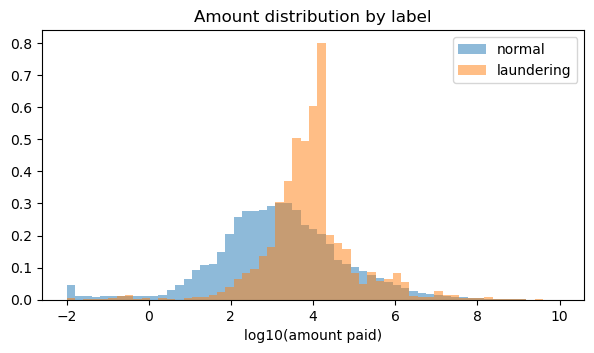

In [11]:
import numpy as np

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(-2, 10, 60)
for label, name in [(0, "normal"), (1, "laundering")]:
    values = np.log10(tx.loc[tx["is_laundering"] == label, "amount_paid"].clip(lower=0.01))
    ax.hist(values, bins=bins, density=True, alpha=0.5, label=name)
ax.set_xlabel("log10(amount paid)")
ax.set_title("Amount distribution by label")
ax.legend()
plt.show()

In [12]:
medians = (
    tx.groupby(["payment_currency", "is_laundering"], observed=True)["amount_paid"]
    .median()
    .unstack()
    .rename(columns={0: "normal", 1: "laundering"})
)
medians["ratio"] = medians["laundering"] / medians["normal"]
medians.sort_values("ratio", ascending=False)

is_laundering,normal,laundering,ratio
payment_currency,,,
Rupee,"65,328.0000","640,426.2300",9.8032
Saudi Riyal,"3,451.2800","31,131.0000",9.0201
Swiss Franc,782.8900,"6,260.6700",7.9969
Euro,744.5000,"5,154.4950",6.9234
Mexican Peso,"18,853.2300","127,554.8450",6.7657
US Dollar,901.4800,"5,970.0850",6.6225
Yen,"95,794.7300","633,401.4300",6.6121
Canadian Dollar,"1,141.3600","7,498.7250",6.5700
Yuan,"6,053.1600","36,582.2250",6.0435


**Finding:** Amounts are heavily skewed and span 15 currencies, so means are not meaningful and medians are used. The median laundering amount is 8,667 against 1,411 for normal transactions, about six times higher. On a log scale, normal amounts are spread widely, while laundering is concentrated between roughly 1,000 and 20,000, with a sharp peak just above 10,000 and a steep drop after it. Amount paid equals amount received in 98.58% of rows, and the remaining 1.42% are the cross currency transactions, so only one amount column is needed. Because raw amounts are not comparable across currencies, the model uses log amount together with the amount relative to the typical value for its currency. The difference holds within every currency: the median laundering amount is between 3.2 and 9.8 times the median normal amount in all 15 currencies, so the signal is not an effect of which currencies laundering uses.

## 7. Self transfers

Rows where the sending and receiving account are the same.

In [13]:
tx["self_transfer"] = (
    (tx["from_account"].astype(str) == tx["to_account"].astype(str))
    & (tx["from_bank"] == tx["to_bank"])
)
print(f"self transfers: {tx['self_transfer'].sum():,} ({tx['self_transfer'].mean():.2%})")
print()
print(
    tx.groupby("self_transfer")["is_laundering"]
    .agg(rows="size", laundering="sum")
)
print()
print(pd.crosstab(tx["payment_format"], tx["self_transfer"]))

self transfers: 591,212 (11.64%)

                  rows  laundering
self_transfer                     
False          4487133        5166
True            591212          11

self_transfer     False   True 
payment_format                 
ACH              529450   71347
Bitcoin          119774   26317
Cash             489436    1455
Cheque          1858265    6066
Credit Card     1319148    4176
Reinvestment          0  481056
Wire             171060     795


In [14]:
print(pd.crosstab(tx["cross_currency"], tx["self_transfer"]))

self_transfer     False   True 
cross_currency                 
False           4484942  521233
True               2191   69979


Decide here whether self transfers stay in the training data, become a feature, or are dropped.

**Finding:** Self transfers, where the sending and receiving account are the same, make up 591,212 rows (11.64%) but only 11 of the 5,177 laundering rows. Their laundering rate is about 0.002%, roughly 60 times lower than for transfers between different accounts. Every one of the 481,056 Reinvestment transactions is a self transfer, which explains why that format has no laundering in section 4. Self transfers are kept in the data, because a deployed system would score every transaction and 11 laundering cases would otherwise be lost. A `self_transfer` flag is added as a feature. They are excluded when computing the graph derived features, since a transfer to the same account adds no counterparty and no flow between accounts. Self transfers also explain the cross currency result in section 5: 69,979 of the 72,170 cross currency rows (97%) are self transfers, so in this dataset a currency conversion is almost always an account converting its own money. The absence of laundering in Reinvestment, in cross currency rows, and in self transfers is therefore largely one fact seen three ways.

## 8. Account activity

Laundering in this dataset is built from multi-hop structures, so how connected an account is should matter.

In [15]:
out_deg = tx.groupby("from_account", observed=True).size().rename("out_tx")
in_deg = tx.groupby("to_account", observed=True).size().rename("in_tx")
activity = pd.concat([out_deg, in_deg], axis=1).fillna(0).astype(int)

print(f"accounts seen in transactions: {len(activity):,}")
print(activity.describe(percentiles=[0.5, 0.9, 0.99]).T)

accounts seen in transactions: 515,080
              count   mean      std    min    50%     90%     99%          max
out_tx 515,080.0000 9.8593 285.1487 0.0000 2.0000 28.0000 91.0000 168,672.0000
in_tx  515,080.0000 9.8593  12.9741 0.0000 2.0000 29.0000 50.0000   1,084.0000


In [16]:
laundering_accounts = pd.unique(
    pd.concat([
        tx.loc[tx["is_laundering"] == 1, "from_account"].astype(str),
        tx.loc[tx["is_laundering"] == 1, "to_account"].astype(str),
    ])
)
activity["touches_laundering"] = activity.index.astype(str).isin(laundering_accounts)

print(f"accounts touching at least one laundering row: {activity['touches_laundering'].sum():,}")
print()
print(activity.groupby("touches_laundering")[["out_tx", "in_tx"]].median())

accounts touching at least one laundering row: 6,357

                    out_tx   in_tx
touches_laundering                
False               2.0000  2.0000
True                4.0000 13.0000


Note for feature work: any per account count used as a model feature must be computed only from transactions earlier than the row being scored. The totals above use the whole period and are for description only.

**Finding:** 515,080 accounts appear in the transactions, and most are quiet: the median account has 2 outgoing and 2 incoming transactions. Outgoing activity is far more uneven than incoming, with a maximum of 168,672 outgoing transactions for one account against 1,084 incoming, so a few hub accounts dominate sending. 6,357 accounts appear in at least one laundering row. Their median activity is 4 outgoing and 13 incoming transactions, against 2 and 2 for other accounts. Part of this gap is a counting effect, because busier accounts have more chances to appear in a laundering row, but the size of the incoming difference suggests account level activity carries signal. These totals cover the whole period and include self transfers, so they are descriptive only. Model features will count only transactions earlier than the row being scored and will exclude self transfers.

## 9. Accounts file

Accounts are matched on bank ID and account number together, because a few account numbers appear under more than one bank.

In [17]:
accounts = pd.read_csv(ACCOUNTS_FILE)
accounts.columns = ["bank_name", "bank_id", "account", "entity_id", "entity_name"]

print(f"rows: {len(accounts):,}")
print(f"unique accounts: {accounts['account'].nunique():,}")
print(f"unique entities: {accounts['entity_id'].nunique():,}")
print(f"unique banks: {accounts['bank_id'].nunique():,}")
print(f"account numbers listed more than once: {accounts['account'].duplicated().sum():,}")
accounts.head()

rows: 518,581
unique accounts: 518,573
unique entities: 166,207
unique banks: 30,470
account numbers listed more than once: 8


,bank_name,bank_id,account,entity_id,entity_name
0,Portugal Bank #4507,331579,80B779D80,80062E240,Sole Proprietorship #50438
1,Canada Bank #27,210,809D86900,800C998A0,Corporation #33520
2,UK Bank #33,21884,80812BE00,800C47F50,Partnership #35397
3,Germany Bank #4815,32742,81047F300,80096F0B0,Corporation #48813
4,National Bank of Harrisburg,127390,80BD8CF00,800FB8760,Corporation #889


In [18]:
accounts["entity_type"] = accounts["entity_name"].str.replace(r"\s*#\d+$", "", regex=True)
accounts["bank_group"] = accounts["bank_name"].str.replace(r"\s*#\d+$", "", regex=True)

print(accounts["entity_type"].value_counts())
print()
print(accounts["bank_group"].value_counts().head(15))

entity_type
Partnership            189683
Corporation            172351
Sole Proprietorship    149048
Country                  6692
Individual                740
Direct                     67
Name: count, dtype: int64

bank_group
Germany Bank        32733
Switzerland Bank    24949
China Bank          23489
France Bank         21416
India Bank          19359
Israel Bank         19248
UK Bank             17982
Italy Bank          17433
Japan Bank          17156
Crytpo Bank         14358
Spain Bank          14313
Australia Bank      13652
Canada Bank         13420
Russia Bank         13351
Mexico Bank          9051
Name: count, dtype: int64


In [19]:
tx_accounts = pd.concat([
    tx[["from_bank", "from_account"]].set_axis(["bank_id", "account"], axis=1),
    tx[["to_bank", "to_account"]].set_axis(["bank_id", "account"], axis=1),
]).astype({"account": str}).drop_duplicates()

joined = tx_accounts.merge(
    accounts[["bank_id", "account"]].drop_duplicates(),
    on=["bank_id", "account"], how="left", indicator=True,
)
print(f"distinct (bank, account) pairs in transactions: {len(tx_accounts):,}")
print(f"found in accounts file: {(joined['_merge'] == 'both').mean():.2%}")

distinct (bank, account) pairs in transactions: 515,088
found in accounts file: 100.00%


In [20]:
known = set(zip(accounts["bank_id"], accounts["account"]))

sample = tx[tx["from_bank"] != tx["to_bank"]].head(200_000)

correct = [
    (b, a) in known
    for b, a in zip(sample["from_bank"], sample["from_account"].astype(str))
]
swapped = [
    (b, a) in known
    for b, a in zip(sample["from_bank"], sample["to_account"].astype(str))
]

print(f"from_bank paired with from_account: {sum(correct) / len(sample):.2%} found")
print(f"from_bank paired with to_account:   {sum(swapped) / len(sample):.2%} found")

from_bank paired with from_account: 100.00% found
from_bank paired with to_account:   0.00% found


The join coverage decides whether the agent tools can rely on the accounts file for every account they see.

**Finding:** The accounts file lists 518,581 accounts owned by 166,207 entities across 30,470 banks, about 3 accounts per entity. Every one of the 515,088 distinct bank and account pairs in the transactions is found in it, so account details are available for any transaction a model or agent sees. About 3,500 listed accounts never transact. Eight account numbers appear under more than one bank, so accounts are always identified by bank and account number together. The same join confirms the column mapping from section 1: sending banks match the first account column for 100% of a 200,000 row sample and the second for 0%. Account owners are almost entirely businesses (partnerships, corporations and sole proprietorships), with only 740 accounts held by individuals. Bank names include a country, which gives each account a jurisdiction. Entity type and bank country are used as account level features, and the entity link lets the investigation agent view all accounts owned by the same entity.

## 10. Patterns file

Each block is one laundering attempt with a named typology. This is the source for the agent evaluation cases and for error analysis by typology.

In [21]:
def parse_patterns(path):
    rows, attempt_id, typology = [], -1, None
    with open(path, encoding="utf-8") as handle:
        for line in handle:
            line = line.strip()
            if line.startswith("BEGIN LAUNDERING ATTEMPT"):
                attempt_id += 1
                typology = line.split(" - ", 1)[1].split(":")[0].strip()
            elif line and not line.startswith("END LAUNDERING ATTEMPT"):
                rows.append(line.split(",") + [attempt_id, typology])
    return pd.DataFrame(rows, columns=TX_COLS + ["attempt_id", "typology"])


patterns = parse_patterns(PATTERNS_FILE)
patterns["amount_paid"] = patterns["amount_paid"].astype(float)

print(f"attempts: {patterns['attempt_id'].nunique():,}")
print(f"transactions inside attempts: {len(patterns):,}")
print(f"share of all laundering rows: {len(patterns) / n_pos:.1%}")

attempts: 370
transactions inside attempts: 3,209
share of all laundering rows: 62.0%


In [22]:
per_attempt = patterns.groupby(["typology", "attempt_id"]).size().rename("n_tx").reset_index()
(
    per_attempt.groupby("typology")["n_tx"]
    .agg(attempts="size", median_tx="median", max_tx="max", total_tx="sum")
    .sort_values("attempts", ascending=False)
)

,attempts,median_tx,max_tx,total_tx
typology,,,,
CYCLE,54,4.0000,12,287
GATHER-SCATTER,51,14.0000,28,716
BIPARTITE,49,4.0000,15,263
FAN-OUT,48,7.0000,16,342
SCATTER-GATHER,44,14.0000,32,626
STACK,43,10.0000,30,466
RANDOM,41,3.0000,11,191
FAN-IN,40,8.0000,16,318


In [23]:
print(patterns["payment_format"].value_counts())
print()
print("is_laundering values inside patterns:", patterns["is_laundering"].unique())

payment_format
ACH        3208
Bitcoin       1
Name: count, dtype: int64

is_laundering values inside patterns: ['1']


In [24]:
fan_out = patterns[patterns["typology"] == "FAN-OUT"]
print(fan_out.groupby("attempt_id")[["from_account", "to_account"]].nunique().head(10))

            from_account  to_account
attempt_id                          
0                      1          16
7                      1          12
8                      1           2
26                     1          13
35                     1          10
42                     1          12
43                     1           8
47                     1           1
49                     1           9
50                     1           4


In [25]:
riyal = patterns[patterns["payment_currency"] == "Saudi Riyal"]
print(f"pattern transactions in Saudi Riyal: {len(riyal)}")
print(f"attempts involved: {riyal['attempt_id'].nunique()}")
print(riyal.groupby("attempt_id").size().sort_values(ascending=False).head(10))

pattern transactions in Saudi Riyal: 336
attempts involved: 110
attempt_id
316    24
118    20
14     16
344    14
215    12
292    11
253    11
341     7
172     7
361     6
dtype: int64


Laundering rows that are in no pattern form a second group. Error analysis should report recall for both groups.

**Finding:** The patterns file lists 370 laundering attempts containing 3,209 transactions, 62% of all laundering rows. The eight typologies are evenly represented, with 40 to 54 attempts each, but differ in size: cycle, bipartite and random attempts have a median of 3 to 4 transactions, while gather-scatter and scatter-gather have a median of 14. All but one pattern transaction use ACH. The remaining 1,968 laundering rows belong to no listed pattern. Since ACH carries 4,483 laundering rows in total, about 1,275 of the unpatterned rows are ACH and about 693 use other formats, so nearly all laundering outside ACH is also outside the listed patterns. Error analysis will therefore report recall separately for each typology and for patterned against unpatterned laundering. The attempts also provide ready made cases for the agent evaluation set, spread across all eight typologies.

## 11. Proposed split

The proposal below keeps the split inside the dense period and holds the sparse tail apart. Adjust the dates if section 3 shows something different.

In [26]:
SPLITS = {
    "train": ("2022-09-01", "2022-09-06"),
    "validation": ("2022-09-07", "2022-09-08"),
    "test": ("2022-09-09", "2022-09-10"),
    "tail (held apart)": ("2022-09-11", "2022-09-18"),
}

rows = []
for name, (start, end) in SPLITS.items():
    part = tx[(tx["date"] >= start) & (tx["date"] <= end)]
    rows.append({
        "split": name, "from": start, "to": end,
        "rows": len(part), "share_of_rows": len(part) / len(tx),
        "laundering": int(part["is_laundering"].sum()),
        "rate": part["is_laundering"].mean(),
    })
pd.DataFrame(rows).set_index("split")

,from,to,rows,share_of_rows,laundering,rate
split,,,,,,
train,2022-09-01,2022-09-06,3248921,0.6398,2530,0.0008
validation,2022-09-07,2022-09-08,965524,0.1901,1036,0.0011
test,2022-09-09,2022-09-10,862792,0.1699,956,0.0011
tail (held apart),2022-09-11,2022-09-18,1108,0.0002,655,0.5912


**Finding:** The split stays inside the dense period: train on 1 to 6 Sep (3,248,921 rows, 2,530 laundering), validate on 7 to 8 Sep (965,524 rows, 1,036 laundering), and test on 9 to 10 Sep (862,792 rows, 956 laundering), which is 64%, 19% and 17% of rows. Laundering rates are similar across the three parts, between 0.08% and 0.11%. The tail of 11 to 18 Sep (1,108 rows, 655 laundering) is held apart and reported separately. Each part contains both weekdays and at least one lower volume day, except validation, which is two weekdays.

## 12. Summary and decisions

This summary becomes the opening of `docs/MODELLING.md`.

| Question | Answer |
|---|---|
| Rows and laundering rate | 5,078,345 transactions, 5,177 laundering (0.10%, about 1 in 981) |
| Usable date range | 1 to 10 Sep 2022. The tail of 11 to 18 Sep (1,108 rows, 59% laundering) is held apart |
| Shortcut columns | Payment format (ACH holds 86.6% of laundering) and payment currency (Saudi Riyal at four times the usual rate). Both are ablated |
| Treatment of self transfers | Kept, flagged with a `self_transfer` feature, and excluded from graph derived features. They also account for 97% of cross currency rows and all Reinvestment rows |
| Accounts join coverage | 100% of bank and account pairs found. Accounts are identified by bank and account number together |
| Final split | Train 1 to 6 Sep, validation 7 to 8 Sep, test 9 to 10 Sep (64%, 19%, 17% of rows) |
| First feature set | Log amount, amount relative to the typical value for its currency, hour of day, self transfer flag, entity type, bank country, and per account counts of past incoming and outgoing transactions and distinct counterparties |
| Baseline to beat | Flagging every ACH transaction gives 86.6% recall at 0.75% precision |

**Open questions for the modelling notebook:**
- How much performance remains when payment format and payment currency are removed?
- Is unpatterned laundering (1,968 rows) harder to detect than patterned laundering, as expected?
- Which trailing window works best for the per account features, given only six days of training data?
- Hour 0 has about three times the volume of other hours. Is hour of day a useful feature or another artifact?
- Are the nine exact duplicate rows worth removing, or do they make no measurable difference?